In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Настройка размеров графиков
plt.rcParams['figure.figsize'] = (14, 8)

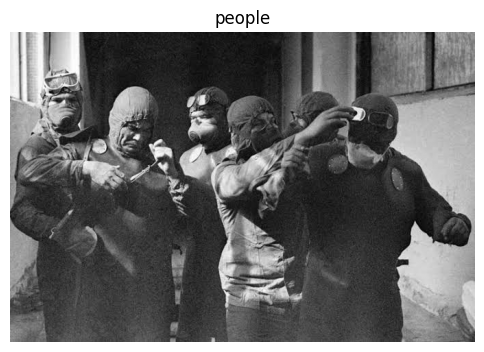

In [3]:
# Загрузка и перевод в серый
image = cv2.imread('/people_me.jpg')

if image is None:
    raise FileNotFoundError("Изображение не найдено")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap="gray")
plt.title("people")
plt.axis("off")
plt.show()

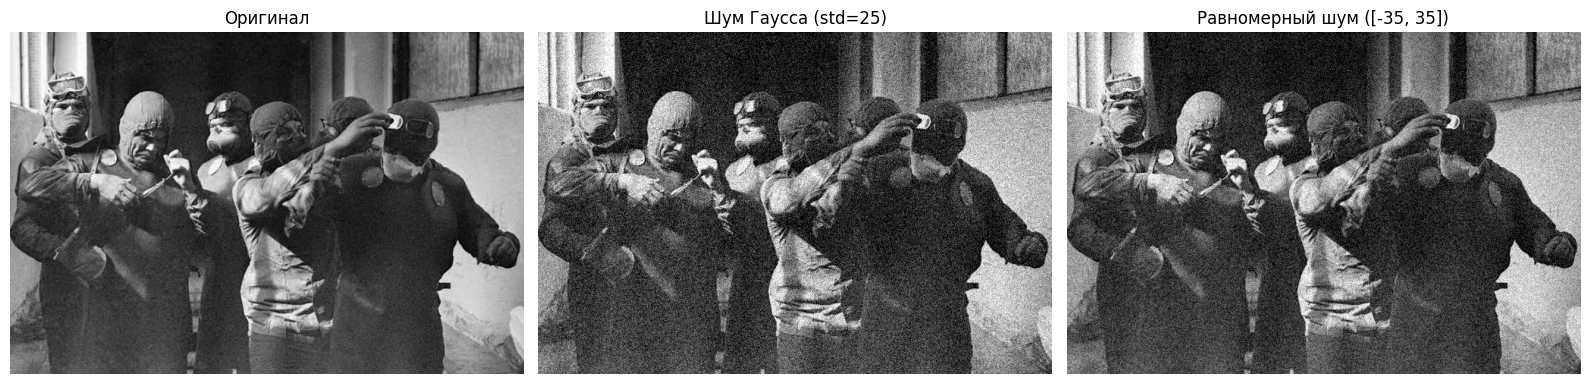

In [4]:
# 1. Шум Гаусса
mean_gauss = 0
stddev_gauss = 25
gauss_noise = np.random.normal(mean_gauss, stddev_gauss, image_gray.shape)
noisy_gauss = np.clip(image_gray.astype(np.float32) + gauss_noise, 0, 255).astype(np.uint8)

# 2. Постоянный (равномерно распределенный) шум
low_val = -35
high_val = 35
uniform_noise = np.random.uniform(low_val, high_val, image_gray.shape)
noisy_uniform = np.clip(image_gray.astype(np.float32) + uniform_noise, 0, 255).astype(np.uint8)

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title("Оригинал")
axes[0].axis('off')

axes[1].imshow(noisy_gauss, cmap='gray')
axes[1].set_title(f"Шум Гаусса (std={stddev_gauss})")
axes[1].axis('off')

axes[2].imshow(noisy_uniform, cmap='gray')
axes[2].set_title(f"Равномерный шум ([{low_val}, {high_val}])")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [19]:
def evaluate_filters(noisy_img, clean_img, noise_name=""):

    experiments = {}

    # 1. Фильтр Гаусса (4 вариации)
    experiments['Gaussian (3x3, sigma=1)'] = cv2.GaussianBlur(noisy_img, (3, 3), 1.0)
    experiments['Gaussian (5x5, sigma=1)'] = cv2.GaussianBlur(noisy_img, (5, 5), 1.0)
    experiments['Gaussian (5x5, sigma=1.5)'] = cv2.GaussianBlur(noisy_img, (5, 5), 1.5)
    experiments['Gaussian (7x7, sigma=2)'] = cv2.GaussianBlur(noisy_img, (7, 7), 2.0)

    # 2. Медианный фильтр (3 вариации)
    experiments['Median (k=3)'] = cv2.medianBlur(noisy_img, 3)
    experiments['Median (k=5)'] = cv2.medianBlur(noisy_img, 5)
    experiments['Median (k=7)'] = cv2.medianBlur(noisy_img, 7)

    # 3. Билатеральный фильтр (3 вариации)
    experiments['Bilateral (d=5, sColor=50, sSpace=50)'] = cv2.bilateralFilter(noisy_img, d=5, sigmaColor=50, sigmaSpace=50)
    experiments['Bilateral (d=9, sColor=75, sSpace=75)'] = cv2.bilateralFilter(noisy_img, d=9, sigmaColor=75, sigmaSpace=75)
    experiments['Bilateral (d=9, sColor=150, sSpace=150)'] = cv2.bilateralFilter(noisy_img, d=9, sigmaColor=150, sigmaSpace=150)

    # 4. Фильтр нелокальных средних NLM (3 вариации)
    experiments['NLM (h=20, tw=30, sw=11)'] = cv2.fastNlMeansDenoising(noisy_img, None, h=20, templateWindowSize=30, searchWindowSize=11)
    experiments['NLM (h=10, tw=7, sw=21)'] = cv2.fastNlMeansDenoising(noisy_img, None, h=10, templateWindowSize=7, searchWindowSize=21)
    experiments['NLM (h=8, tw=12, sw=19)'] = cv2.fastNlMeansDenoising(noisy_img, None, h=8, templateWindowSize=12, searchWindowSize=19)

    # Вывод таблицы
    results = []
    print(f"\n{'='*55}\nРезультаты фильтрации для: {noise_name}\n{'='*55}")
    print(f"{'Конфигурация фильтра':<50}")
    print("-" * 55)

    for name, img in experiments.items():
        results.append((name, img))
        print(f"{name:<50}")

    return results


Результаты фильтрации для: Шум Гаусса
Конфигурация фильтра                              
-------------------------------------------------------
Gaussian (3x3, sigma=1)                           
Gaussian (5x5, sigma=1)                           
Gaussian (5x5, sigma=1.5)                         
Gaussian (7x7, sigma=2)                           
Median (k=3)                                      
Median (k=5)                                      
Median (k=7)                                      
Bilateral (d=5, sColor=50, sSpace=50)             
Bilateral (d=9, sColor=75, sSpace=75)             
Bilateral (d=9, sColor=150, sSpace=150)           
NLM (h=20, tw=30, sw=11)                          
NLM (h=10, tw=7, sw=21)                           
NLM (h=8, tw=12, sw=19)                           


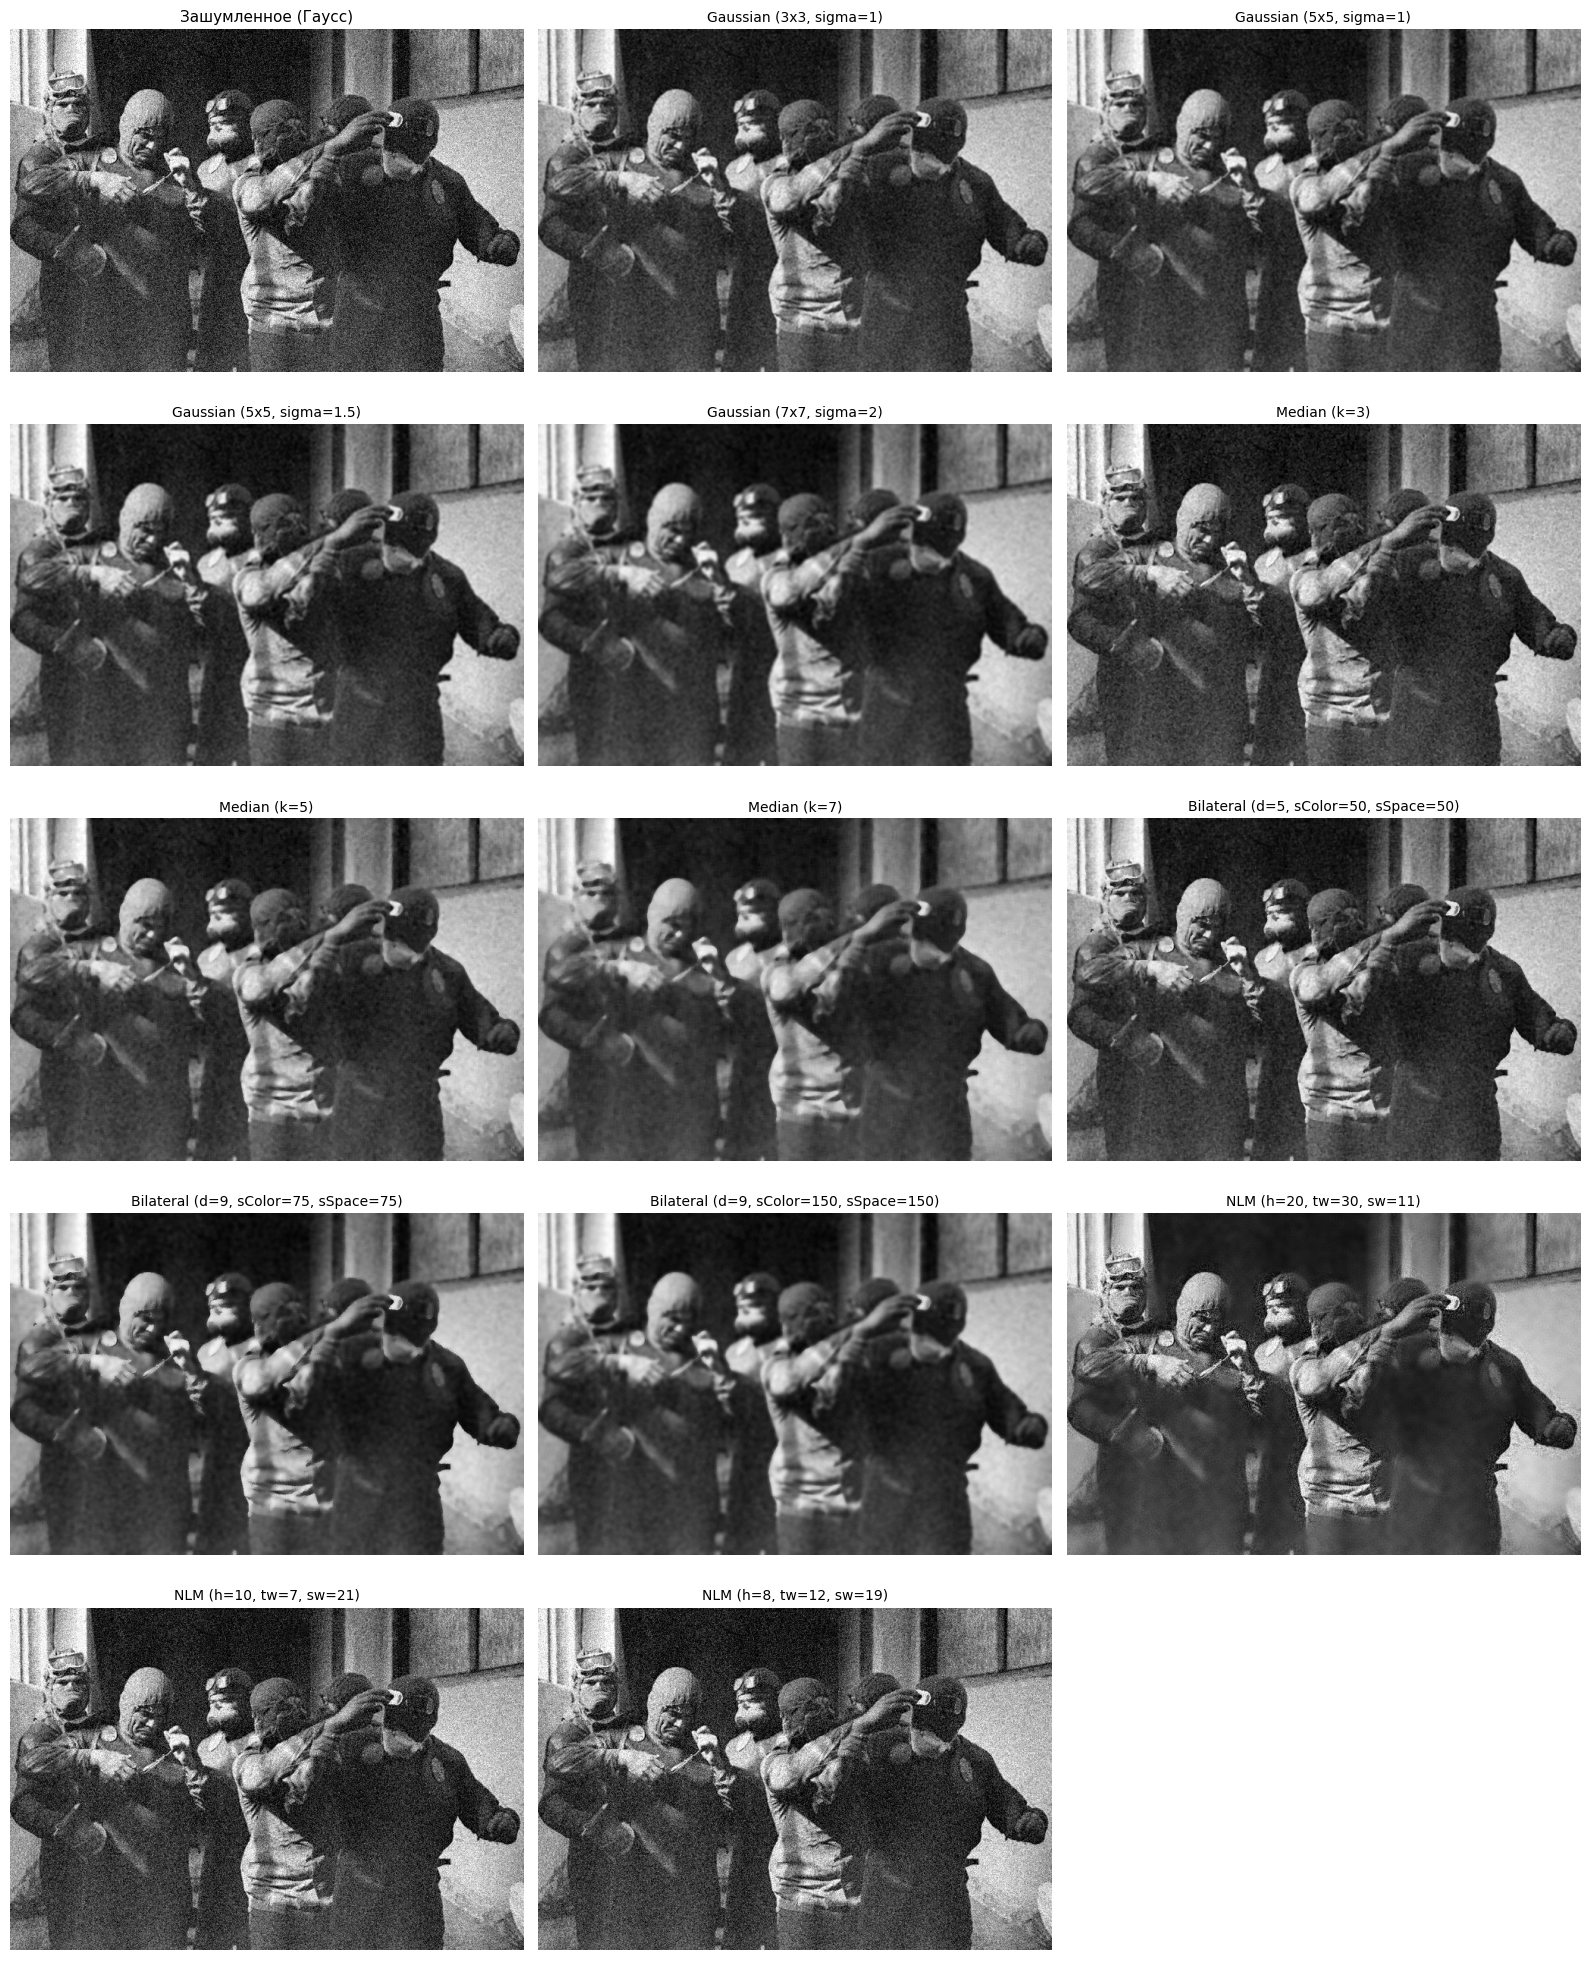

In [20]:
# Запуск для шума Гаусса
results_gauss = evaluate_filters(noisy_gauss, image_gray, noise_name="Шум Гаусса")

# Сетка 5 рядов на 3 колонки (всего 15 ячеек: 1 зашумленное + 13 фильтров)
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
axes_flat = axes.flatten()

# Первая ячейка — зашумленное изображение
axes_flat[0].imshow(noisy_gauss, cmap='gray')
axes_flat[0].set_title("Зашумленное (Гаусс)", fontsize=11)
axes_flat[0].axis('off')

# Вывод каждого профильтрованного изображения
for idx, (name, img) in enumerate(results_gauss):
    axes_flat[idx + 1].imshow(img, cmap='gray')
    axes_flat[idx + 1].set_title(name, fontsize=10)
    axes_flat[idx + 1].axis('off')

# Скрываем последнюю неиспользуемую 15-ю ячейку
axes_flat[-1].axis('off')

plt.tight_layout()
plt.show()

***ЛУЧШИЕ ФИЛЬТРЫ:***

 **Фильтр нелокальных средних (Non-Local Means)** (изображение с параметрами h=10,tw=7, sw=21)

*   показывает наилучший результат подавления как гауссова, так и равномерного шума.

**Билатеральный фильтр (Bilateral Filter)** (изображение с параметрами d=5,scolor=50,sspace=50

*   занимает второе место. Он успешно сохраняет резкие контуры и не дает изображению плыть